# Random Forest — Binary Classification

تطبيق **Random Forest** على مشكلة **Binary Classification** (Breast Cancer)، مع حساب **Accuracy, Precision, Recall, F1, Loss**،
ومقارنته مع **Decision Tree** واحدة ومع **Logistic Regression** (من الاسايمنت السابق).

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn import metrics as skm

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## 1) الداتا سيت — Breast Cancer Wisconsin

نفس داتا الاسايمنت السابق (مضمّنة بـ `scikit-learn`، ما بتحتاج إنترنت):

- **569** عيّنة و **30** feature رقمية محسوبة من صور الخلايا.
- **الـ Target:** `1` = **Malignant (خبيث)** ← الـ positive class، `0` = **Benign (حميد)**.

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df["target"] = 1 - df["target"]          # 1 = malignant (positive), 0 = benign
feature_names = list(data.feature_names)
print("Shape:", df.shape)
df.head()

Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


Class counts: {'Benign (0)': 357, 'Malignant (1)': 212}
Missing values: 0


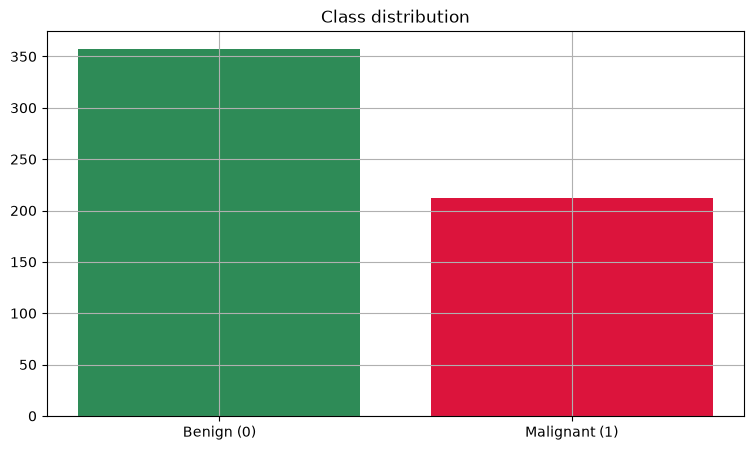

In [3]:
counts = df["target"].value_counts().sort_index()
print("Class counts:", {"Benign (0)": int(counts[0]), "Malignant (1)": int(counts[1])})
print("Missing values:", int(df.isna().sum().sum()))
plt.bar(["Benign (0)", "Malignant (1)"], counts.values, color=["seagreen", "crimson"])
plt.title("Class distribution"); plt.show()

## 2) تجهيز الداتا

- تقسيم **80% train / 20% test** مع `stratify` (نفس التقسيم تبع الاسايمنت السابق، `random_state=42`).
- **ملاحظة مهمة:** الـ Random Forest **ما بيحتاج Standardization**، لأن الشجرة بتقسم على عتبة (threshold) لكل feature لحالها، فمقياس الـ feature ما بيأثر. بنعمل scaling بس للـ Logistic Regression اللي بنقارن فيها.

In [4]:
X = df.drop(columns="target").values
y = df["target"].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (455, 30) | Test: (114, 30)


## 3) شو هو الـ Random Forest؟

**Decision Tree:** شجرة بتسأل أسئلة متتالية على الـ features (مثلاً: `worst radius > 16.8`؟) لحد ما توصل لقرار. كل تقسيم بينختار حتى يقلّل الـ **Gini impurity**:
$$Gini = 1 - \sum_{k} p_k^2$$
مشكلتها: الشجرة الوحدة العميقة بتحفظ الداتا (**overfitting**، variance عالي).

**Random Forest** = مجموعة كبيرة من الشجرات، وكل شجرة:
1. **Bootstrap (Bagging):** بتتدرّب على عيّنة عشوائية من الـ train **مع الإرجاع**.
2. **Feature randomness:** بكل تقسيم بتختار من مجموعة عشوائية من الـ features بس (`max_features`، الافتراضي $\sqrt{30} \approx 5$).

**التوقع:** متوسط احتمالات كل الشجرات (soft voting):
$$\hat{p}(x) = \frac{1}{T}\sum_{t=1}^{T} \hat{p}_t(x)$$

هالعشوائية بتخلّي الشجرات **مختلفة عن بعض**، فلما ناخد متوسطهم الأخطاء بتلغي بعضها ← **variance أقل** بدون ما يزيد الـ bias كتير.

> **ملاحظة:** الـ Random Forest **ما بيتدرّب بـ gradient descent**، فما في optimizer ولا learning rate. الـ hyperparameters المهمة هي: `n_estimators`، `max_depth`، `max_features`، `min_samples_leaf`.

## 4) الـ Metrics — محسوبة من الصفر

نفس تعريفات الاسايمنت السابق:

- **Accuracy** $= \dfrac{TP+TN}{TP+TN+FP+FN}$
- **Precision** $= \dfrac{TP}{TP+FP}$ — من اللي توقعناهم خبيثين، قديش فعلاً خبيثين؟
- **Recall** $= \dfrac{TP}{TP+FN}$ — من كل الخبيثين، قديش اكتشفنا؟
- **F1** $= 2\cdot\dfrac{Precision \cdot Recall}{Precision + Recall}$
- **Loss** = Binary Cross-Entropy (Log Loss) على الاحتمالات $\hat{p}$ اللي بيطلعها الموديل:
$$L = -\frac{1}{n}\sum\Big[y\log\hat{p} + (1-y)\log(1-\hat{p})\Big]$$

In [5]:
def confusion(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp, tn, fp, fn

def bce_loss(y, p, eps=1e-15):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def compute_metrics(model, X, y):
    p = model.predict_proba(X)[:, 1]
    y_pred = (p >= 0.5).astype(int)
    tp, tn, fp, fn = confusion(y, y_pred)
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    return {
        "Loss": bce_loss(y, p),
        "Accuracy": (tp + tn) / len(y),
        "Precision": precision,
        "Recall": recall,
        "F1": 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0,
    }

## 5) Baseline 1: Decision Tree واحدة

شجرة وحدة بدون أي تحديد للعمق — حتى نشوف مشكلة الـ overfitting.

In [6]:
tree = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
print("Tree depth:", tree.get_depth(), "| leaves:", tree.get_n_leaves())
pd.DataFrame([
    pd.Series(compute_metrics(tree, X_train, y_train), name="Decision Tree (train)"),
    pd.Series(compute_metrics(tree, X_test, y_test), name="Decision Tree (test)"),
]).round(4)

Tree depth: 8 | leaves: 24


,Loss,Accuracy,Precision,Recall,F1
Decision Tree (train),0.0000,1.0000,1.0000,1.0000,1.0000
Decision Tree (test),2.4238,0.9298,0.9048,0.9048,0.9048


> لاحظ: الـ train accuracy = 100% والـ train loss = 0 (الشجرة حفظت الداتا)، بس الـ test أسوأ بكتير — وهاد **overfitting**.
> وكمان الـ test loss عالي جداً لأن الشجرة بتعطي احتمالات 0 أو 1 بس، فلما تغلط بتغلط **بثقة كاملة** والـ log loss بيعاقب هالشي بقوة.

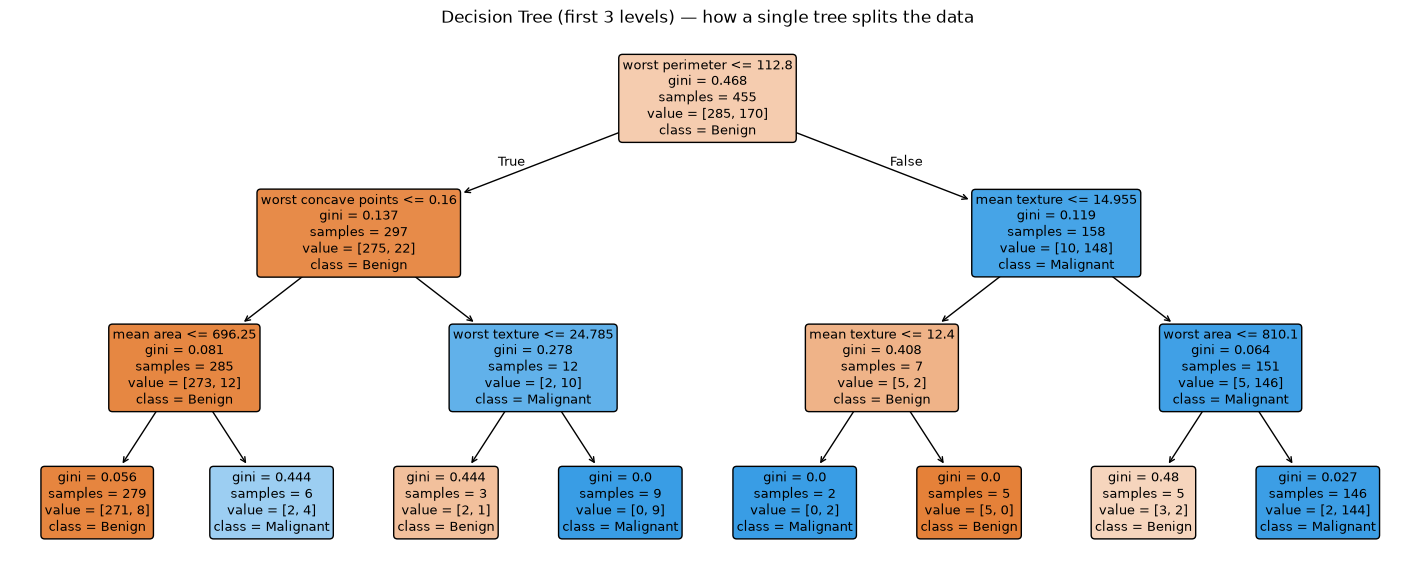

In [7]:
plt.figure(figsize=(18, 7))
plot_tree(DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train),
          feature_names=feature_names, class_names=["Benign", "Malignant"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (first 3 levels) — how a single tree splits the data")
plt.show()

## 6) Random Forest

In [8]:
start = time.time()
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
rf.fit(X_train, y_train)
train_time = time.time() - start

print(f"Training time: {train_time:.2f} s")
print(f"Out-of-bag (OOB) accuracy: {rf.oob_score_:.4f}")

Training time: 0.46 s
Out-of-bag (OOB) accuracy: 0.9604


**OOB score:** كل شجرة ما شافت تقريباً 37% من الـ train (بسبب الـ bootstrap)، فمنقدر نقيّم كل عيّنة بالشجرات اللي ما شافتها ← تقدير مجاني لأداء الموديل بدون ما نلمس الـ test.

## 7) النتائج والتقييم

In [9]:
scaler = StandardScaler().fit(X_train)
class Scaled:   # wrapper so compute_metrics works on scaled inputs
    def __init__(self, m): self.m = m
    def predict_proba(self, X): return self.m.predict_proba(scaler.transform(X))
logreg = Scaled(LogisticRegression(max_iter=5000).fit(scaler.transform(X_train), y_train))

results = pd.DataFrame([
    pd.Series(compute_metrics(rf, X_train, y_train), name="Random Forest (train)"),
    pd.Series(compute_metrics(rf, X_test, y_test), name="Random Forest (test)"),
    pd.Series(compute_metrics(tree, X_test, y_test), name="Decision Tree (test)"),
    pd.Series(compute_metrics(logreg, X_test, y_test), name="Logistic Regression (test)"),
]).round(4)
results

,Loss,Accuracy,Precision,Recall,F1
Random Forest (train),0.0323,1.0000,1.0000,1.0000,1.0000
Random Forest (test),0.1135,0.9737,1.0000,0.9286,0.9630
Decision Tree (test),2.4238,0.9298,0.9048,0.9048,0.9048
Logistic Regression (test),0.0773,0.9649,0.9750,0.9286,0.9512


### تأكيد: الـ metrics تبعنا بتطابق دوال sklearn

In [10]:
p = rf.predict_proba(X_test)[:, 1]
y_pred = rf.predict(X_test)
pd.DataFrame({
    "Ours (from scratch)": compute_metrics(rf, X_test, y_test),
    "sklearn.metrics": {
        "Loss": skm.log_loss(y_test, p),
        "Accuracy": skm.accuracy_score(y_test, y_pred),
        "Precision": skm.precision_score(y_test, y_pred),
        "Recall": skm.recall_score(y_test, y_pred),
        "F1": skm.f1_score(y_test, y_pred),
    },
}).round(6)

,Ours (from scratch),sklearn.metrics
Loss,0.113483,0.113483
Accuracy,0.973684,0.973684
Precision,1.000000,1.000000
Recall,0.928571,0.928571
F1,0.962963,0.962963


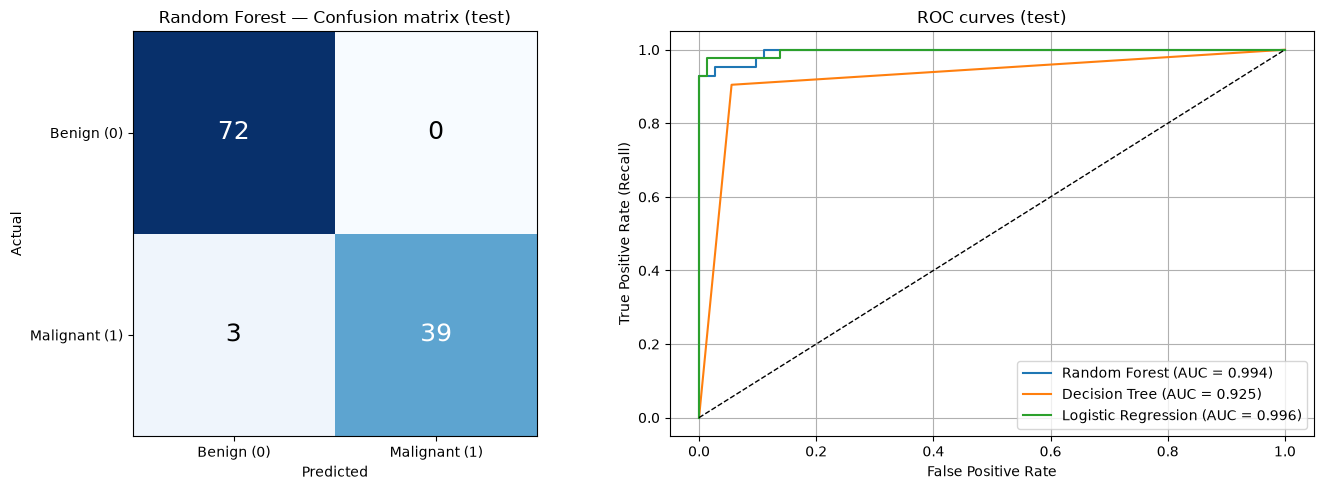

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tp, tn, fp, fn = confusion(y_test, rf.predict(X_test))
cm = np.array([[tn, fp], [fn, tp]])
axes[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=18,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
axes[0].set_xticks([0, 1], ["Benign (0)", "Malignant (1)"])
axes[0].set_yticks([0, 1], ["Benign (0)", "Malignant (1)"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title("Random Forest — Confusion matrix (test)"); axes[0].grid(False)

for name, m in [("Random Forest", rf), ("Decision Tree", tree), ("Logistic Regression", logreg)]:
    fpr, tpr, _ = skm.roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC = {skm.auc(fpr, tpr):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].set_title("ROC curves (test)"); axes[1].legend()
plt.tight_layout(); plt.show()

## 8) تأثير عدد الشجرات (`n_estimators`)

بالـ Random Forest، عدد الشجرات بيلعب دور شبيه بالـ epochs بالاسايمنتات السابقة: منشوف كيف بتتغيّر الـ metrics كل ما نزيد شجرات.
بنستخدم `warm_start=True` حتى نضيف شجرات على نفس الغابة بدل ما نعيد التدريب من الأول.

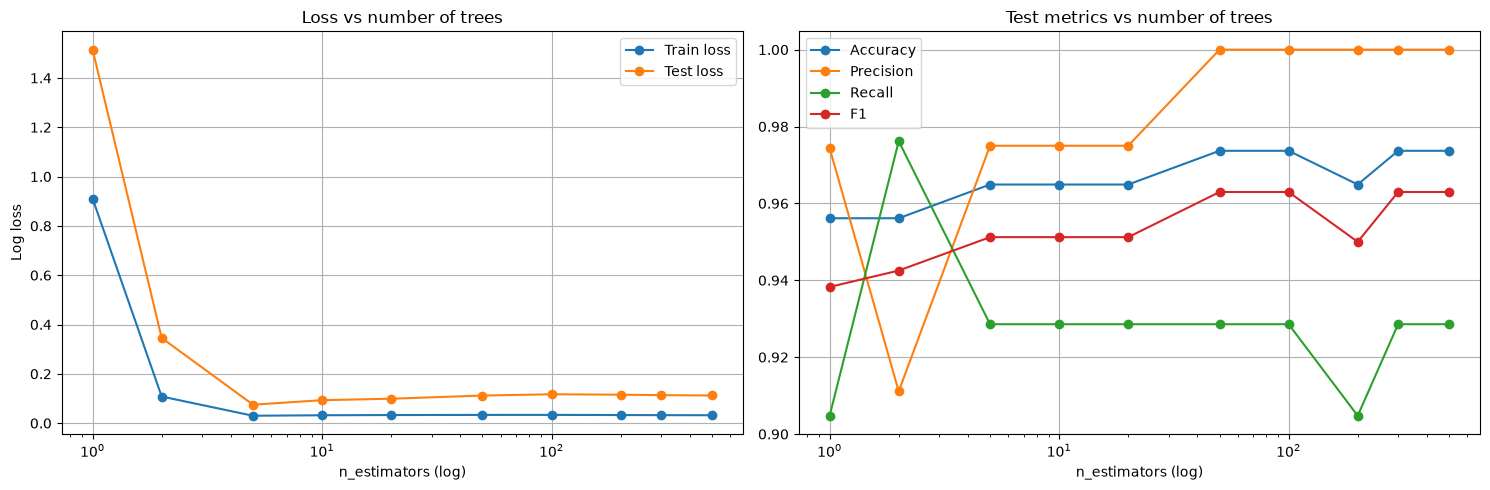

,Loss,Accuracy,Precision,Recall,F1,Train loss,OOB acc
n_estimators,,,,,,,
1,1.5149,0.9561,0.9744,0.9048,0.9383,0.9109,NaN
2,0.3455,0.9561,0.9111,0.9762,0.9425,0.1079,NaN
5,0.0748,0.9649,0.9750,0.9286,0.9512,0.0300,NaN
10,0.0931,0.9649,0.9750,0.9286,0.9512,0.0320,NaN
20,0.0990,0.9649,0.9750,0.9286,0.9512,0.0328,0.9451
50,0.1118,0.9737,1.0000,0.9286,0.9630,0.0333,0.9538
100,0.1170,0.9737,1.0000,0.9286,0.9630,0.0334,0.9604
200,0.1154,0.9649,1.0000,0.9048,0.9500,0.0329,0.9538
300,0.1135,0.9737,1.0000,0.9286,0.9630,0.0323,0.9604


In [12]:
sizes = [1, 2, 5, 10, 20, 50, 100, 200, 300, 500]
rows = []
forest = RandomForestClassifier(warm_start=True, oob_score=True, random_state=SEED, n_jobs=-1)
for n in sizes:
    forest.set_params(n_estimators=n)
    with warnings.catch_warnings():   # OOB warns when there are too few trees
        warnings.simplefilter("ignore", UserWarning)
        forest.fit(X_train, y_train)
    r = compute_metrics(forest, X_test, y_test)
    r["Train loss"] = compute_metrics(forest, X_train, y_train)["Loss"]
    r["OOB acc"] = forest.oob_score_ if n >= 20 else np.nan   # OOB is unreliable with very few trees
    rows.append(pd.Series(r, name=n))
curve = pd.DataFrame(rows); curve.index.name = "n_estimators"

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(curve.index, curve["Train loss"], "o-", label="Train loss")
axes[0].plot(curve.index, curve["Loss"], "o-", label="Test loss")
axes[0].set_xscale("log"); axes[0].set_xlabel("n_estimators (log)"); axes[0].set_ylabel("Log loss")
axes[0].set_title("Loss vs number of trees"); axes[0].legend()
for col in ["Accuracy", "Precision", "Recall", "F1"]:
    axes[1].plot(curve.index, curve[col], "o-", label=col)
axes[1].set_xscale("log"); axes[1].set_xlabel("n_estimators (log)")
axes[1].set_title("Test metrics vs number of trees"); axes[1].legend()
plt.tight_layout(); plt.show()
curve.round(4)

## 9) تأثير عمق الشجرة (`max_depth`)

العمق بيتحكّم بمدى تعقيد كل شجرة: عمق صغير = **underfitting**، عمق كبير لكل شجرة لحالها = overfitting، بس الغابة بتخفف هالشي.

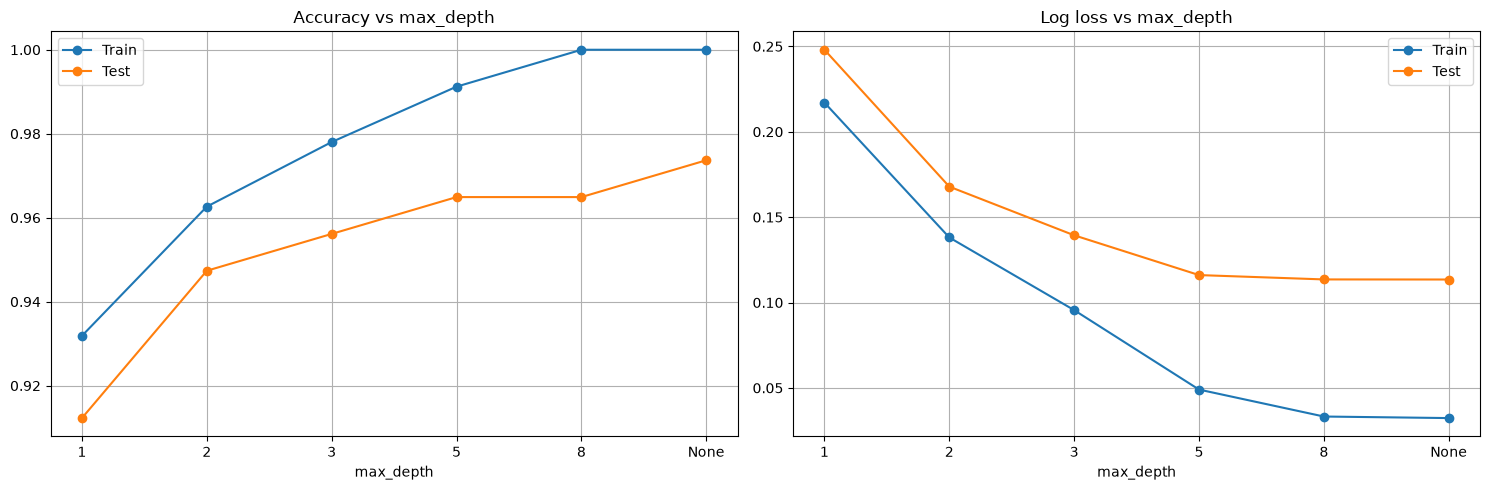

,Train acc,Test acc,Train loss,Test loss,Test F1
max_depth,,,,,
1,0.9319,0.9123,0.2171,0.2480,0.8649
2,0.9626,0.9474,0.1381,0.1679,0.9231
3,0.9780,0.9561,0.0956,0.1394,0.9367
5,0.9912,0.9649,0.0490,0.1161,0.9500
8,1.0000,0.9649,0.0333,0.1135,0.9500
None,1.0000,0.9737,0.0323,0.1135,0.9630


In [13]:
rows = []
for d in [1, 2, 3, 5, 8, None]:
    m = RandomForestClassifier(n_estimators=300, max_depth=d, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
    tr, te = compute_metrics(m, X_train, y_train), compute_metrics(m, X_test, y_test)
    rows.append(pd.Series({"Train acc": tr["Accuracy"], "Test acc": te["Accuracy"],
                           "Train loss": tr["Loss"], "Test loss": te["Loss"], "Test F1": te["F1"]},
                          name=str(d)))
depth = pd.DataFrame(rows); depth.index.name = "max_depth"

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(depth.index, depth["Train acc"], "o-", label="Train"); axes[0].plot(depth.index, depth["Test acc"], "o-", label="Test")
axes[0].set_xlabel("max_depth"); axes[0].set_title("Accuracy vs max_depth"); axes[0].legend()
axes[1].plot(depth.index, depth["Train loss"], "o-", label="Train"); axes[1].plot(depth.index, depth["Test loss"], "o-", label="Test")
axes[1].set_xlabel("max_depth"); axes[1].set_title("Log loss vs max_depth"); axes[1].legend()
plt.tight_layout(); plt.show()
depth.round(4)

## 10) Hyperparameter Tuning — GridSearchCV

بندوّر على أفضل تركيبة hyperparameters باستخدام **5-fold cross-validation** على الـ train بس (الـ test ما منلمسه)، ومنختار حسب الـ **F1**.

In [14]:
param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [None, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
    "min_samples_leaf": [1, 2, 4],
}
grid = GridSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=-1), param_grid,
    scoring="f1", cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=-1)
start = time.time()
grid.fit(X_train, y_train)
print(f"Search time: {time.time() - start:.1f} s  ({len(grid.cv_results_['params'])} combinations x 5 folds)")
print("Best params:", grid.best_params_)
print(f"Best CV F1: {grid.best_score_:.4f}")

best_rf = grid.best_estimator_
pd.DataFrame([
    pd.Series(compute_metrics(rf, X_test, y_test), name="Random Forest — default (test)"),
    pd.Series(compute_metrics(best_rf, X_test, y_test), name="Random Forest — tuned (test)"),
]).round(4)

Search time: 87.6 s  (54 combinations x 5 folds)
Best params: {'max_depth': 5, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 100}
Best CV F1: 0.9615


,Loss,Accuracy,Precision,Recall,F1
Random Forest — default (test),0.1135,0.9737,1.0,0.9286,0.963
Random Forest — tuned (test),0.1167,0.9737,1.0,0.9286,0.963


## 11) Feature Importance

ميزة مهمة للـ Random Forest: بيقول أي features أثّرت أكتر بالقرار (حسب قديش كل feature قلّلت الـ Gini impurity بكل الشجرات).

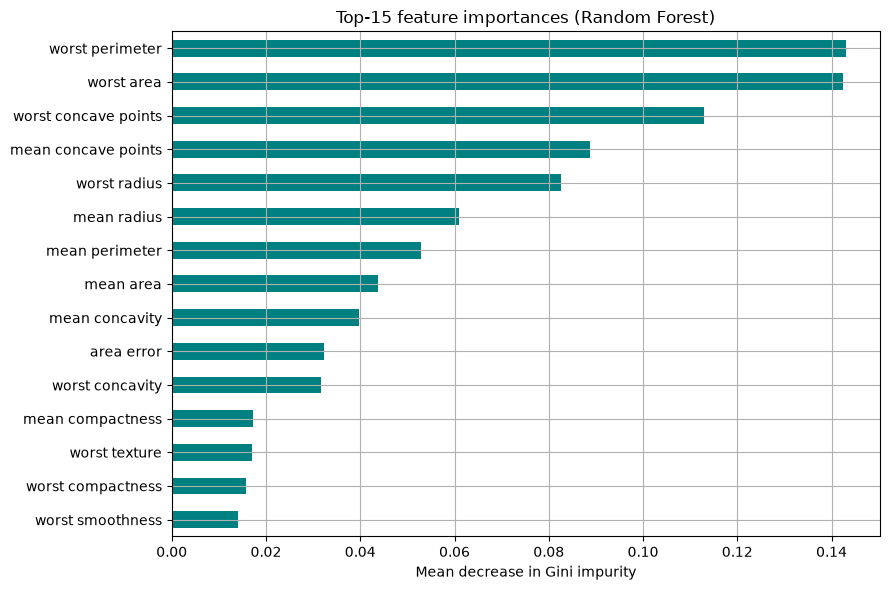

,importance
worst perimeter,0.1431
worst area,0.1424
worst concave points,0.1130
mean concave points,0.0887
worst radius,0.0826
mean radius,0.0610
mean perimeter,0.0529
mean area,0.0438
mean concavity,0.0398
area error,0.0322


In [15]:
imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values()
imp.tail(15).plot.barh(figsize=(9, 6), color="teal")
plt.title("Top-15 feature importances (Random Forest)"); plt.xlabel("Mean decrease in Gini impurity")
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).head(10).round(4).to_frame("importance")

## 12) الخلاصة

| Model (test) | Loss | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|
| Decision Tree | 2.4238 | 0.9298 | 0.9048 | 0.9048 | 0.9048 |
| Logistic Regression | **0.0773** | 0.9649 | 0.9750 | 0.9286 | 0.9512 |
| **Random Forest** | 0.1135 | **0.9737** | **1.0000** | 0.9286 | **0.9630** |

- **الشجرة الوحدة عملت overfitting واضح:** 100% على الـ train بس 93% على الـ test، والـ test loss ضخم (2.42) لأنها بتغلط بثقة كاملة (احتمال 0 أو 1).
- **الـ Random Forest حلّ المشكلة:** جمع 300 شجرة مختلفة رفع الـ test accuracy لـ **97.4%** و F1 لـ **0.963**، ونزّل الـ loss من 2.42 لـ 0.11 لأن متوسط الشجرات بيعطي احتمالات معتدلة بدل 0/1.
- **Precision = 1.0:** ولا حالة حميدة انصنّفت خبيثة. **Recall = 0.929:** 3 حالات خبيثة من 42 ما انكشفت — طبياً هاد الخطأ الأخطر، وممكن نقلّله بتنزيل الـ threshold تحت 0.5.
- **مقارنة مع Logistic Regression:** الـ Random Forest أعلى بالـ Accuracy و Precision و F1، بس الـ Logistic Regression عندها **loss أقل** — احتمالاتها أدق (better calibrated)، بينما الـ RF بيطلع احتمالات أقل حدّة.
- **عدد الشجرات:** القفزة الكبيرة من شجرة وحدة لـ 5 شجرات، وبعد ~50 شجرة النتائج بتستقر. زيادة الشجرات **ما بتعمل overfitting** — بس بتزيد وقت التدريب.
- **العمق:** `max_depth` صغير (1–2) = underfitting، ومع زيادة العمق الأداء بيتحسّن لحد ما يستقر.
- **GridSearchCV:** أفضل تركيبة (`max_depth=5, max_features=0.5, min_samples_leaf=2, n_estimators=100`) أعطت نفس نتيجة الإعدادات الافتراضية على الـ test — الـ Random Forest قوي بالإعدادات الافتراضية وما بيحتاج tuning كتير.
- **أهم الـ features:** `worst perimeter`, `worst area`, `worst concave points` — يعني حجم الخلية وشكل حوافها هي أقوى مؤشر على إنو الورم خبيث.